# 03 — Perspective Rectification of Sign Boards with a 4-Point Homography

Notebook `02` left one clear failure on realistic photos: a board seen from an **oblique angle** (about 45°) becomes a **trapezoid** in the image. The pipeline's deskew step only corrects **in-plane rotation** (a minimum-area rectangle), so the letters stay distorted and OCR fails.

The geometrically correct fix is a **homography**: find the board's four corners, then map them to an upright rectangle with `cv2.getPerspectiveTransform` (the same idea used by document-scanner apps).

This notebook:
1. Simulates out-of-plane rotation (yaw) of a sign board with a pinhole camera model, from 0° to 75°
2. Compares the **rotation-only deskew** reader from notebook `02` with a **homography rectification** reader
3. Reports the angle range where each method still reads the correct command

In [1]:
import importlib.util, subprocess, sys
missing = [p for p in ("easyocr",) if importlib.util.find_spec(p) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import warnings
warnings.filterwarnings("ignore")
import os, time, difflib
import cv2, numpy as np, torch
import matplotlib.pyplot as plt
import easyocr

DEVICE = "GPU" if torch.cuda.is_available() else "CPU"
reader = easyocr.Reader(["en"], gpu=torch.cuda.is_available(), verbose=False)
os.makedirs("results", exist_ok=True)
print("Ready | running on:", DEVICE)

Ready | running on: CPU


## 1. Shared helpers (from notebook 02)

In [2]:
def show(images, titles, cols=4, size=3.2, save=None):
    rows = (len(images) + cols - 1) // cols
    plt.figure(figsize=(cols * size, rows * size * 0.8))
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(im if im.ndim == 2 else cv2.cvtColor(im, cv2.COLOR_BGR2RGB),
                   cmap="gray" if im.ndim == 2 else None)
        plt.title(t, fontsize=9); plt.axis("off")
    plt.tight_layout()
    if save:
        plt.savefig(save, dpi=110, bbox_inches="tight")
    plt.show()

def make_sign(text, w=400, h=200):
    sign = np.full((h, w, 3), 255, dtype=np.uint8)
    cv2.rectangle(sign, (10, 10), (w - 10, h - 10), (0, 0, 200), -1)
    scale = 3 if len(text) <= 4 else 2.2
    (tw, th), _ = cv2.getTextSize(text, cv2.FONT_HERSHEY_SIMPLEX, scale, 8)
    cv2.putText(sign, text, ((w - tw) // 2, (h + th) // 2),
                cv2.FONT_HERSHEY_SIMPLEX, scale, (255, 255, 255), 8)
    return sign

def enhance(img):
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img
    gray = cv2.normalize(gray, None, 0, 255, cv2.NORM_MINMAX)
    gray = cv2.createCLAHE(clipLimit=3.0, tileGridSize=(8, 8)).apply(gray)
    gray = cv2.medianBlur(gray, 5)
    h, w = gray.shape
    if max(h, w) < 600:
        f = 600 / max(h, w)
        gray = cv2.resize(gray, None, fx=f, fy=f, interpolation=cv2.INTER_CUBIC)
    blur = cv2.GaussianBlur(gray, (0, 0), 3)
    return cv2.addWeighted(gray, 1.6, blur, -0.6, 0)

ALLOW = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"
COMMANDS = {"STOP": "stop", "LEFT": "turn left", "RIGHT": "turn right", "GO": "move forward"}

def ocr_best(img, **kw):
    res = reader.readtext(img, **kw)
    if not res:
        return "-", 0.0
    _, text, conf = max(res, key=lambda r: r[2])
    return text, float(conf)

def match_command(text):
    text = text.upper().replace("0", "O").replace("1", "I").replace("5", "S")
    m = difflib.get_close_matches(text, COMMANDS.keys(), n=1, cutoff=0.6)
    return m[0] if m else None

def red_mask(frame):
    hsv = cv2.cvtColor(cv2.medianBlur(frame, 7), cv2.COLOR_BGR2HSV)
    m = cv2.bitwise_or(cv2.inRange(hsv, (0, 100, 30), (10, 255, 255)),
                       cv2.inRange(hsv, (170, 100, 30), (180, 255, 255)))
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((5, 5), np.uint8))
    return cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))

def largest_board_contour(frame, min_area=800):
    mask = red_mask(frame)
    cnts, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cnts = [c for c in cnts if min_area < cv2.contourArea(c) < 0.5 * mask.size]
    return max(cnts, key=cv2.contourArea) if cnts else None

## 2. Simulating an oblique view
The board is placed in 3D at a fixed distance and rotated about its vertical axis (**yaw**) by θ, then projected through a pinhole camera. The resulting four image corners define the homography used to paste the board into the frame, so the trapezoid is geometrically exact.

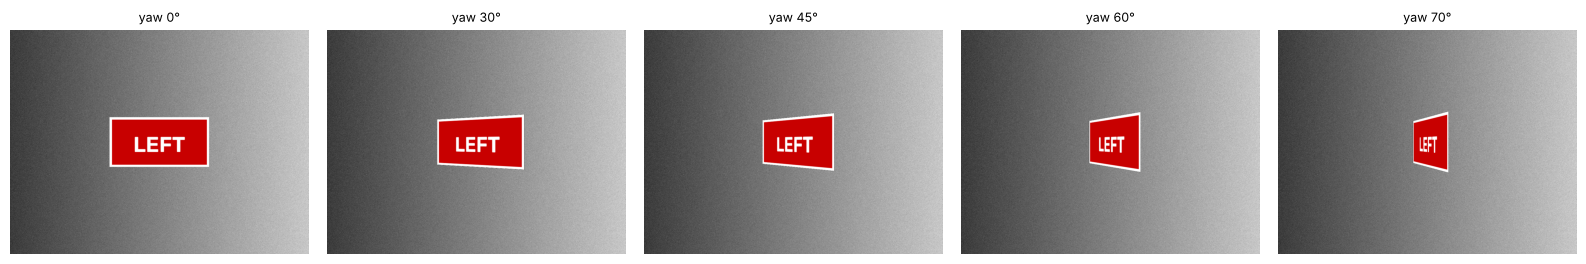

In [3]:
np.random.seed(0)
g = np.tile(np.linspace(60, 200, 1080, dtype=np.float32), (810, 1)) + np.random.normal(0, 12, (810, 1080))
BACKGROUND = cv2.cvtColor(np.clip(g, 0, 255).astype(np.uint8), cv2.COLOR_GRAY2BGR)

def oblique_view(sign, yaw_deg, roll_deg=0, board_w=0.8, dist=2.0, f=900):
    """Render `sign` rotated by yaw (out-of-plane) and roll (in-plane) onto the background."""
    h, w = sign.shape[:2]
    bw, bh = board_w, board_w * h / w
    corners = np.array([[-bw/2, -bh/2, 0], [bw/2, -bh/2, 0], [bw/2, bh/2, 0], [-bw/2, bh/2, 0]])
    y, r = np.radians(yaw_deg), np.radians(roll_deg)
    Ry = np.array([[np.cos(y), 0, np.sin(y)], [0, 1, 0], [-np.sin(y), 0, np.cos(y)]])
    Rz = np.array([[np.cos(r), -np.sin(r), 0], [np.sin(r), np.cos(r), 0], [0, 0, 1]])
    P = corners @ (Rz @ Ry).T + np.array([0, 0, dist])
    H_img, W_img = BACKGROUND.shape[:2]
    img_pts = np.stack([f * P[:, 0] / P[:, 2] + W_img / 2, f * P[:, 1] / P[:, 2] + H_img / 2], 1).astype(np.float32)
    src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])
    M = cv2.getPerspectiveTransform(src, img_pts)
    warped = cv2.warpPerspective(sign, M, (W_img, H_img))
    mask = cv2.warpPerspective(np.full((h, w), 255, np.uint8), M, (W_img, H_img))
    out = BACKGROUND.copy()
    out[mask > 0] = warped[mask > 0]
    return out

demo_angles = [0, 30, 45, 60, 70]
show([oblique_view(make_sign("LEFT"), a) for a in demo_angles],
     [f"yaw {a}°" for a in demo_angles], cols=5, save="results/oblique_views.png")

## 3. Method A — rotation-only deskew (notebook 02)
`minAreaRect` fits the smallest rotated rectangle around the board and rotates it upright. For a trapezoid this keeps the perspective distortion: one side of the text stays compressed. The multi-strategy reader (`read_sign` from notebook 02) is kept unchanged as the baseline.

In [4]:
def deskew_crop(frame):
    c = largest_board_contour(frame)
    if c is None:
        return None
    (cx, cy), (w, h), angle = cv2.minAreaRect(c)
    if w < h:
        angle -= 90; w, h = h, w
    while angle > 45: angle -= 180
    while angle < -45: angle += 180
    M = cv2.getRotationMatrix2D((cx, cy), angle, 1.0)
    rot = cv2.warpAffine(frame, M, (frame.shape[1], frame.shape[0]))
    return cv2.getRectSubPix(rot, (int(w), int(h)), (cx, cy))

def read_deskew(frame):
    """Notebook-02 multi-strategy reader: deskewed crop +/- enhance, full frame +/- enhance."""
    cands = []
    crop = deskew_crop(frame)
    if crop is not None:
        cands.append(ocr_best(enhance(crop), allowlist=ALLOW, rotation_info=[180]))
        cands.append(ocr_best(crop, rotation_info=[180]))
    cands.append(ocr_best(frame, rotation_info=[180]))
    cands.append(ocr_best(enhance(frame), allowlist=ALLOW))
    valid = [c for c in cands if match_command(c[0])]
    return max(valid or cands, key=lambda c: c[1]), crop

## 4. Method B — 4-point homography rectification
1. Approximate the board contour with a polygon (`approxPolyDP`); if it is not a quadrilateral, fall back to the four extreme points of its convex hull.
2. Order the corners (top-left, top-right, bottom-right, bottom-left).
3. Map the corners to an upright rectangle with the board's **known aspect ratio** (2:1 template) using `cv2.getPerspectiveTransform`. Using the object model matters: the apparent width of an oblique board is foreshortened, so estimating the aspect from the image would squash the letters.
4. Read the rectified board (plain, upper-case allow-list, and enhanced), with a full-frame fallback.

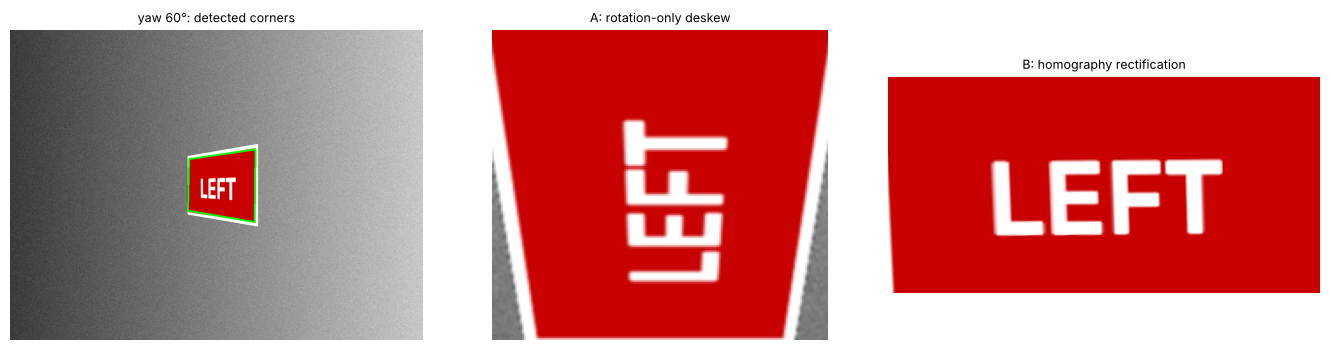

In [5]:
def order_corners(pts):
    pts = pts.reshape(4, 2).astype(np.float32)
    s, d = pts.sum(1), np.diff(pts, axis=1).ravel()
    return np.float32([pts[np.argmin(s)], pts[np.argmin(d)], pts[np.argmax(s)], pts[np.argmax(d)]])

def board_corners(frame):
    c = largest_board_contour(frame)
    if c is None:
        return None
    peri = cv2.arcLength(c, True)
    for eps in (0.02, 0.03, 0.05):
        approx = cv2.approxPolyDP(c, eps * peri, True)
        if len(approx) == 4:
            return order_corners(approx)
    hull = cv2.convexHull(c).reshape(-1, 2).astype(np.float32)
    s, d = hull.sum(1), np.diff(hull, axis=1).ravel()
    return np.float32([hull[np.argmin(s)], hull[np.argmin(d)], hull[np.argmax(s)], hull[np.argmax(d)]])

BOARD_ASPECT = 2.0   # known width:height of the sign template (the object model)

def rectify(frame, corners, out_h=200, aspect=BOARD_ASPECT):
    """Map the 4 detected corners to an upright rectangle with the board's known aspect ratio."""
    out_w = int(out_h * aspect)
    dst = np.float32([[0, 0], [out_w - 1, 0], [out_w - 1, out_h - 1], [0, out_h - 1]])
    H = cv2.getPerspectiveTransform(corners, dst)
    return cv2.warpPerspective(frame, H, (out_w, out_h))

def read_homography(frame):
    cands = []
    corners = board_corners(frame)
    rect = None
    if corners is not None:
        rect = rectify(frame, corners)
        cands.append(ocr_best(rect, rotation_info=[180]))
        cands.append(ocr_best(rect, allowlist=ALLOW, rotation_info=[180]))
        cands.append(ocr_best(enhance(rect), allowlist=ALLOW, rotation_info=[180]))
    cands.append(ocr_best(frame, rotation_info=[180]))
    valid = [c for c in cands if match_command(c[0])]
    return max(valid or cands, key=lambda c: c[1]), rect

frame = oblique_view(make_sign("LEFT"), 60)
(_, _), crop_a = read_deskew(frame)
(_, _), crop_b = read_homography(frame)
vis = frame.copy()
cv2.polylines(vis, [board_corners(frame).astype(int)], True, (0, 255, 0), 3)
show([vis, crop_a, crop_b], ["yaw 60°: detected corners", "A: rotation-only deskew", "B: homography rectification"],
     cols=3, size=4.5, save="results/rectification_example.png")

## 5. Sweep over viewing angles
Four commands × eight yaw angles, plus a small in-plane roll (10°) to make the case harder. A trial passes only if the reader returns the correct command.

In [6]:
WORDS = ["STOP", "LEFT", "RIGHT", "GO"]
ANGLES = [0, 15, 30, 45, 55, 65, 70, 75]

rows = []
t0 = time.time()
for word in WORDS:
    sign = make_sign(word)
    for a in ANGLES:
        frame = oblique_view(sign, a, roll_deg=10)
        (ta, ca), _ = read_deskew(frame)
        (tb, cb), _ = read_homography(frame)
        rows.append({"word": word, "yaw": a,
                     "A_text": ta, "A_ok": match_command(ta) == word,
                     "B_text": tb, "B_ok": match_command(tb) == word})
print(f"{len(rows)} trials in {time.time() - t0:.0f} s on {DEVICE}\n")

print(f"{'yaw':>4} | {'A: deskew (pass/4)':>18} | {'B: homography (pass/4)':>22}")
print("-" * 52)
acc_a, acc_b = [], []
for a in ANGLES:
    ra = [r for r in rows if r["yaw"] == a]
    pa, pb = sum(r["A_ok"] for r in ra), sum(r["B_ok"] for r in ra)
    acc_a.append(pa / 4); acc_b.append(pb / 4)
    print(f"{a:>3}° | {pa:>18} | {pb:>22}")
tot_a = sum(r["A_ok"] for r in rows); tot_b = sum(r["B_ok"] for r in rows)
print(f"\nTotal: A = {tot_a}/{len(rows)}   B = {tot_b}/{len(rows)}")

32 trials in 514 s on CPU

 yaw | A: deskew (pass/4) | B: homography (pass/4)
----------------------------------------------------
  0° |                  4 |                      4
 15° |                  4 |                      4
 30° |                  4 |                      4
 45° |                  4 |                      4
 55° |                  4 |                      4
 65° |                  3 |                      4
 70° |                  2 |                      4
 75° |                  2 |                      4

Total: A = 27/32   B = 32/32


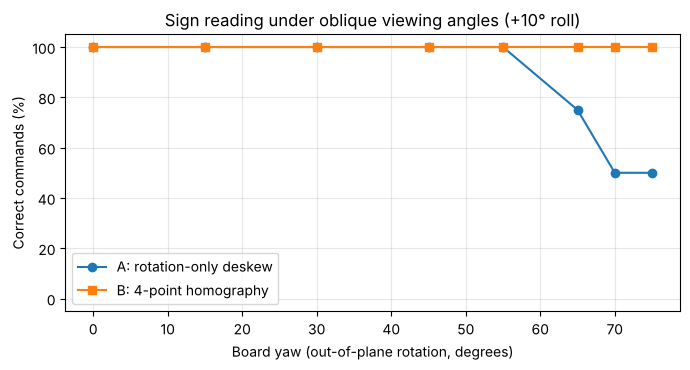

Failures:
  LEFT  yaw 75°  A read 'IFFT'      B read 'LEFT'
  RIGHT yaw 70°  A read '9'         B read 'RIGHT'
  RIGHT yaw 75°  A read 'HH'        B read 'RIGHT'
  GO    yaw 65°  A read '8'         B read 'GO'
  GO    yaw 70°  A read '8'         B read 'GO'


In [7]:
plt.figure(figsize=(7, 3.8))
plt.plot(ANGLES, [100 * x for x in acc_a], "o-", label="A: rotation-only deskew")
plt.plot(ANGLES, [100 * x for x in acc_b], "s-", label="B: 4-point homography")
plt.xlabel("Board yaw (out-of-plane rotation, degrees)")
plt.ylabel("Correct commands (%)")
plt.ylim(-5, 105); plt.grid(alpha=0.3); plt.legend()
plt.title("Sign reading under oblique viewing angles (+10° roll)")
plt.tight_layout(); plt.savefig("results/angle_sweep.png", dpi=120); plt.show()

print("Failures:")
for r in rows:
    if not (r["A_ok"] and r["B_ok"]):
        print(f"  {r['word']:5s} yaw {r['yaw']:>2}°  A read {r['A_text']!r:10}  B read {r['B_text']!r}")

## 6. Discussion
- Rotation-only deskew handles in-plane rotation but not perspective: as yaw grows, the far side of the board shrinks and the letters are compressed unevenly.
- Mapping the four detected corners to a rectangle removes the projective distortion before OCR, which is the step the pipeline was missing.
- At extreme angles the board covers few pixels horizontally, so even a perfect homography has little information left — the remaining limit is **resolution**, not geometry.

**Limitations and next steps**
- Corners come from a colour mask; partial occlusion or a red background breaks corner detection. A learned corner/keypoint detector, or **deep homography estimation** between the board template and the image, would be more robust.
- Synthetic yaw is clean; real images add blur, lighting gradients and lens distortion.
- On a moving robot, homographies between consecutive frames could also stabilise the board track and let OCR results be fused over time.